<a href="https://colab.research.google.com/github/Sibitenda/BAchelors_CS/blob/main/Group1_Mall_Customers_Clustering_Practical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Group 1 Practical: Mall Customers: K-means vs Hierarchical Clustering
**Step-by-step practical notebook (100 points)**

This notebook follows Parts A–F of the assignment. Keep `Mall_Customers.csv` in the same folder as this notebook, or update `DATA_PATH` below.


## 0. Install/import packages
Run the install cell only if a package is missing.

In [2]:
# If needed, uncomment and run:
# %pip install pandas numpy matplotlib seaborn scikit-learn scipy

import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Imports complete. Random state:", RANDOM_STATE)

Imports complete. Random state: 42
Imports complete. Random state: 42


## Part A — Data loading and preprocessing

### Task A1. Load the dataset, show the first 10 rows, and identify column types.

In [3]:
import pandas as pd
from google.colab import files
from IPython.display import display
import io

# Step 1: Upload the Mall Customers CSV file
uploaded = files.upload()

# Step 2: Read the uploaded CSV file
file_name = next(iter(uploaded))
raw = pd.read_csv(io.BytesIO(uploaded[file_name]))

# Step 3: Display dataset information
print("Uploaded file:", file_name)
print("Dataset shape:", raw.shape)

# Step 4: Display the first 10 rows
display(raw.head(10))

# Step 5: Display column types
print("\nColumn types:")
display(raw.dtypes.to_frame("dtype"))

Saving Wholesale customers data.csv to Wholesale customers data.csv
Uploaded file: Wholesale customers data.csv
Dataset shape: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185
5,2,3,9413,8259,5126,666,1795,1451
6,2,3,12126,3199,6975,480,3140,545
7,2,3,7579,4956,9426,1669,3321,2566
8,1,3,5963,3648,6192,425,1716,750
9,2,3,6006,11093,18881,1159,7425,2098



Column types:


,dtype
Channel,int64
Region,int64
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicassen,int64


### Task A2. Remove exact duplicate rows and report how many were removed.

In [4]:
before_rows = len(raw)
duplicate_count = int(raw.duplicated().sum())
df = raw.drop_duplicates().copy()
print(f"Exact duplicate rows removed: {duplicate_count}")
print(f"Rows before: {before_rows:,}; rows after: {len(df):,}")

Exact duplicate rows removed: 0
Rows before: 440; rows after: 440


### Task A3. Identify missing values; remove rows with >50% missing fields; impute remaining values.

In [5]:
print("Missing values before cleaning:")
display(df.isna().sum().to_frame("missing_count"))
missing_fraction = df.isna().mean(axis=1)
too_missing = int((missing_fraction > 0.50).sum())
df = df.loc[missing_fraction <= 0.50].copy()
print("Rows removed for >50% missing fields:", too_missing)

# Detect common column-name variations
rename_map = {}
for c in df.columns:
    key = c.strip().lower().replace("_", " ")
    if key in ["annual income (k$)", "annual income (k $)", "annual income"]:
        rename_map[c] = "Annual Income (k$)"
    elif key in ["spending score (1 100)", "spending score (1-100)", "spending score"]:
        rename_map[c] = "Spending Score (1-100)"
    elif key == "customerid":
        rename_map[c] = "CustomerID"
    elif key == "gender":
        rename_map[c] = "Gender"
    elif key == "age":
        rename_map[c] = "Age"
df.rename(columns=rename_map, inplace=True)

numeric_cols = [c for c in ["Age", "Annual Income (k$)", "Spending Score (1-100)"] if c in df.columns]
categorical_cols = [c for c in ["Gender"] if c in df.columns]
for c in numeric_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    df[c] = df[c].fillna(df[c].median())
for c in categorical_cols:
    if df[c].isna().any():
        df[c] = df[c].fillna(df[c].mode().iloc[0])
print("Missing values after cleaning:")
display(df.isna().sum().to_frame("missing_count"))
print("Cleaned shape:", df.shape)
display(df.head())

Missing values before cleaning:


,missing_count
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


Rows removed for >50% missing fields: 0
Missing values after cleaning:


,missing_count
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


Cleaned shape: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


### Task A4–A5. Make a reproducible cleaned copy, set random_state=42, and prepare numeric features.

We exclude `CustomerID` because it is only an identifier. We also exclude `Gender` from the primary clustering model to keep distances based on the three numeric customer attributes; gender is retained for post-clustering interpretation. A one-hot encoded alternative could be tested separately.

In [9]:
# Display the exact column names in your dataset
print("Dataset column names:")
for col in df.columns:
    print(repr(col))

print("\nFirst 5 rows:")
display(df.head())

Dataset column names:
'Channel'
'Region'
'Fresh'
'Milk'
'Grocery'
'Frozen'
'Detergents_Paper'
'Delicassen'

First 5 rows:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [10]:
# Step 1: Create a copy of the uploaded dataset
cleaned_df = df.copy()

# Step 2: Save a reproducible copy
cleaned_df.to_csv("wholesale_customers_cleaned.csv", index=False)

print("Saved: wholesale_customers_cleaned.csv")

# Step 3: Identify the spending features
spending_features = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen"
]

# Step 4: Check that all required features exist
missing_features = [
    col for col in spending_features
    if col not in cleaned_df.columns
]

if missing_features:
    raise ValueError(f"Missing columns: {missing_features}")

# Step 5: Select spending features for clustering
X_original = cleaned_df[spending_features].copy()

print("Original spending data:")
display(X_original.head())

# Step 6: Scale the spending features
from sklearn.preprocessing import RobustScaler
import pandas as pd

scaler = RobustScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X_original),
    columns=spending_features,
    index=cleaned_df.index
)

# Step 7: Display the scaled dataset
print("Scaled spending data:")
display(X_scaled.head())

# Step 8: Verify scaling
print("Scaled feature medians (approximately zero):")
display(X_scaled.median().round(3).to_frame("median"))

# Step 9: Confirm dataset dimensions
print("Original dataset shape:", df.shape)
print("Clustering feature shape:", X_scaled.shape)

Saved: wholesale_customers_cleaned.csv
Original spending data:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


Scaled spending data:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.301680,1.065712,0.329952,-0.466572,0.506787,0.263810
1,-0.104810,1.092934,0.565993,0.083926,0.675670,0.574008
2,-0.155802,0.915816,0.344418,0.312589,0.736512,4.871459
3,0.344850,-0.429714,-0.062862,1.734708,-0.084442,0.582507
4,1.022092,0.315171,0.287260,0.849573,0.262056,2.988314


Scaled feature medians (approximately zero):


,median
Fresh,0.0
Milk,0.0
Grocery,0.0
Frozen,0.0
Detergents_Paper,0.0
Delicassen,0.0


Original dataset shape: (440, 8)
Clustering feature shape: (440, 6)


## Part B — First exploratory data analysis

### Task B1. Descriptive statistics: mean, median, standard deviation and IQR.

In [11]:
stats = pd.DataFrame({
    "mean": X_original.mean(),
    "median": X_original.median(),
    "std": X_original.std(),
    "Q1": X_original.quantile(0.25),
    "Q3": X_original.quantile(0.75)
})
stats["IQR"] = stats["Q3"] - stats["Q1"]
display(stats.round(3))

,mean,median,std,Q1,Q3,IQR
Fresh,12000.298,8504.0,12647.329,3127.75,16933.75,13806.00
Milk,5796.266,3627.0,7380.377,1533.00,7190.25,5657.25
Grocery,7951.277,4755.5,9503.163,2153.00,10655.75,8502.75
Frozen,3071.932,1526.0,4854.673,742.25,3554.25,2812.00
Detergents_Paper,2881.493,816.5,4767.854,256.75,3922.00,3665.25
Delicassen,1524.870,965.5,2820.106,408.25,1820.25,1412.00


### Task B2. Histograms and boxplots; inspect skewness and potential outliers.

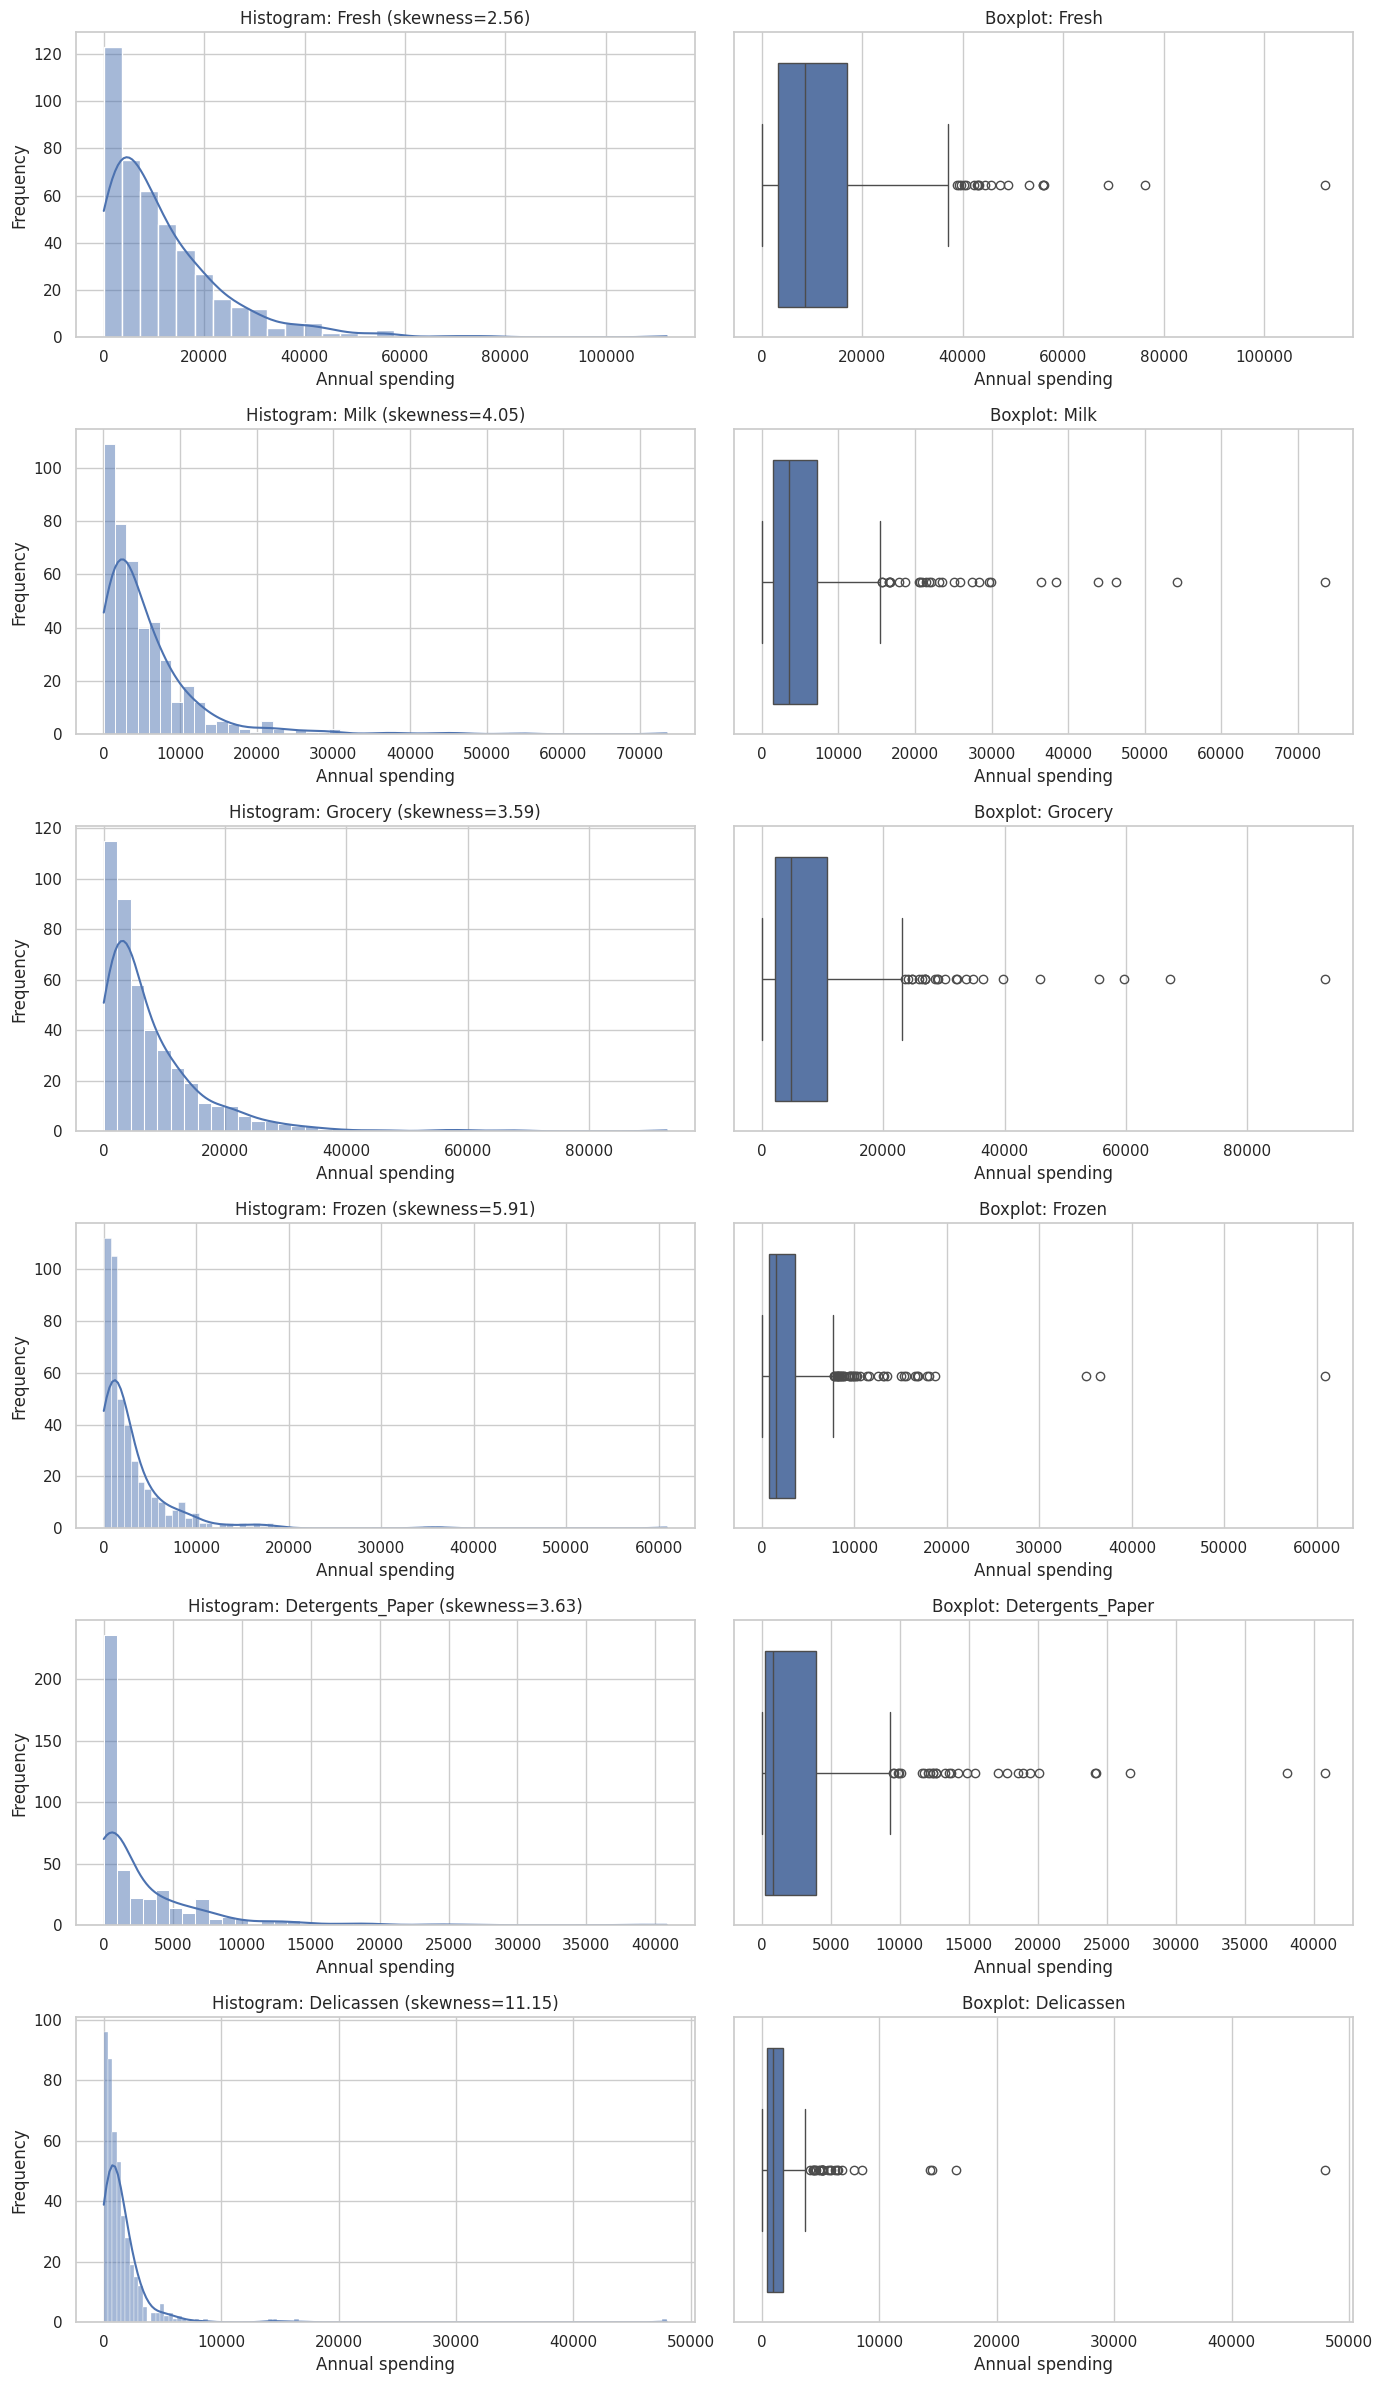

Skewness values:


,Skewness
Fresh,2.561
Milk,4.054
Grocery,3.587
Frozen,5.908
Detergents_Paper,3.632
Delicassen,11.152



Interpretation:
Fresh: Highly positively skewed (skewness = 2.561)
Milk: Highly positively skewed (skewness = 4.054)
Grocery: Highly positively skewed (skewness = 3.587)
Frozen: Highly positively skewed (skewness = 5.908)
Detergents_Paper: Highly positively skewed (skewness = 3.632)
Delicassen: Highly positively skewed (skewness = 11.152)


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Define the spending categories
spending_features = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen"
]

# Step 2: Create histograms and boxplots
fig, axes = plt.subplots(
    len(spending_features), 2,
    figsize=(14, 4 * len(spending_features))
)

for i, col in enumerate(spending_features):

    # Histogram with density curve
    sns.histplot(
        X_original[col],
        kde=True,
        ax=axes[i, 0]
    )
    axes[i, 0].set_title(
        f"Histogram: {col} (skewness={X_original[col].skew():.2f})"
    )
    axes[i, 0].set_xlabel("Annual spending")
    axes[i, 0].set_ylabel("Frequency")

    # Boxplot to identify outliers
    sns.boxplot(
        x=X_original[col],
        ax=axes[i, 1]
    )
    axes[i, 1].set_title(f"Boxplot: {col}")
    axes[i, 1].set_xlabel("Annual spending")

plt.tight_layout()
plt.show()

# Step 3: Calculate skewness for all spending categories
print("Skewness values:")
display(
    X_original[spending_features]
    .skew()
    .to_frame("Skewness")
    .round(3)
)

# Step 4: Interpret skewness
print("\nInterpretation:")
for col in spending_features:
    skew = X_original[col].skew()

    if skew > 1:
        interpretation = "Highly positively skewed"
    elif skew > 0.5:
        interpretation = "Moderately positively skewed"
    elif skew < -0.5:
        interpretation = "Negatively skewed"
    else:
        interpretation = "Approximately symmetric or mildly skewed"

    print(f"{col}: {interpretation} (skewness = {skew:.3f})")

### Task B3. Pairwise scatter plots coloured by Gender (when available).

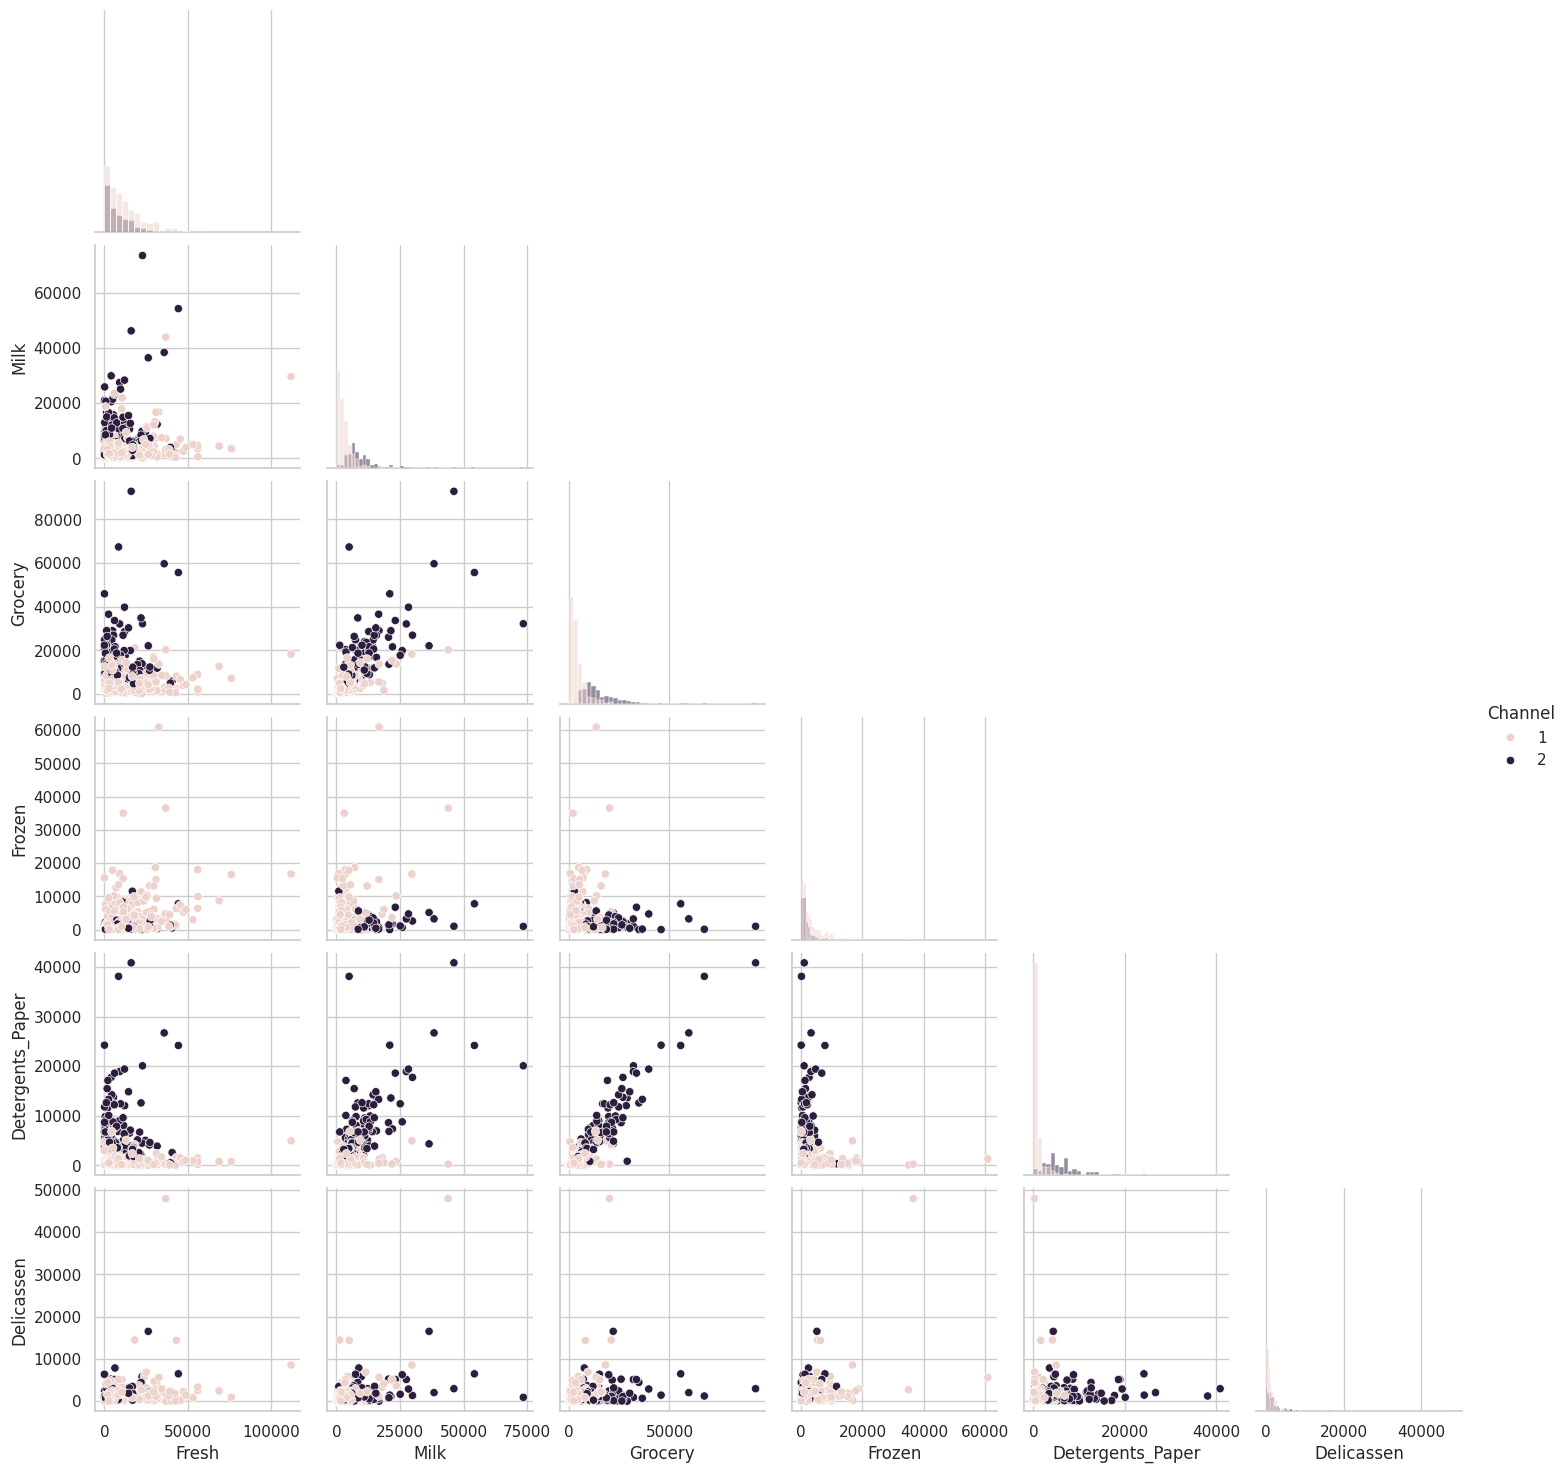

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

# Step 1: Select spending features and Channel for interpretation
plot_df = cleaned_df[
    spending_features + ["Channel"]
].copy()

# Step 2: Create pairwise plots
sns.pairplot(
    plot_df,
    vars=spending_features,
    hue="Channel",
    diag_kind="hist",
    corner=True
)

# Step 3: Display the plots
plt.show()

### Task B4. Correlation matrix and heatmap.

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Fresh,1.000,0.101,-0.012,0.346,-0.102,0.245
Milk,0.101,1.000,0.728,0.124,0.662,0.406
Grocery,-0.012,0.728,1.000,-0.040,0.925,0.205
Frozen,0.346,0.124,-0.040,1.000,-0.132,0.391
Detergents_Paper,-0.102,0.662,0.925,-0.132,1.000,0.069
Delicassen,0.245,0.406,0.205,0.391,0.069,1.000


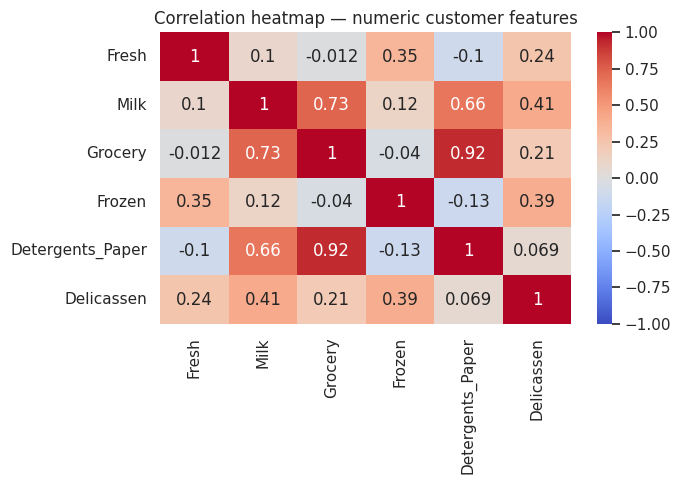

Interpretation prompt: identify the strongest positive/negative correlation and state whether it is weak, moderate, or strong.


In [17]:
corr = X_original.corr(numeric_only=True)
display(corr.round(3))
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation heatmap — numeric customer features")
plt.tight_layout()
plt.show()
print("Interpretation prompt: identify the strongest positive/negative correlation and state whether it is weak, moderate, or strong.")

## Part C — Feature engineering and transformations

Create at least two derived features. `Income_to_Spend` compares income with spending score (the +1 avoids division by zero); `AgeGroupCode` gives an ordinal code for age bands. For a fair baseline comparison, the primary clustering below uses the original three numeric features; you can switch to engineered features and compare results.

In [20]:
import numpy as np
import pandas as pd

# Step 1: Create a copy of the cleaned dataset
df_features = cleaned_df.copy()

# Step 2: Define the spending categories
spending_features = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen"
]

# Step 3: Calculate total spending across all categories
df_features["TotalSpend"] = df_features[spending_features].sum(axis=1)

# Step 4: Calculate the proportion spent on Fresh products
df_features["ProportionFresh"] = np.where(
    df_features["TotalSpend"] > 0,
    df_features["Fresh"] / df_features["TotalSpend"],
    0
)

# Step 5: Calculate log-transformed total spending
df_features["LogTotalSpend"] = np.log1p(df_features["TotalSpend"])

# Step 6: Display the original and engineered features
display(
    df_features[
        spending_features
        + ["TotalSpend", "ProportionFresh", "LogTotalSpend"]
    ].head(10)
)

# Step 7: Define the primary model features
print("Primary clustering features:", spending_features)

print("Engineered features:")
print("- TotalSpend: total spending across all six categories.")
print("- ProportionFresh: share of total spending on fresh products.")
print("- LogTotalSpend: reduces the influence of very large spending values.")

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,TotalSpend,ProportionFresh,LogTotalSpend
0,12669,9656,7561,214,2674,1338,34112,0.371394,10.437434
1,7057,9810,9568,1762,3293,1776,33266,0.212139,10.412321
2,6353,8808,7684,2405,3516,7844,36610,0.173532,10.508104
3,13265,1196,4221,6404,507,1788,27381,0.484460,10.217641
4,22615,5410,7198,3915,1777,5185,46100,0.490564,10.738590
5,9413,8259,5126,666,1795,1451,26710,0.352415,10.192831
6,12126,3199,6975,480,3140,545,26465,0.458190,10.183616
7,7579,4956,9426,1669,3321,2566,29517,0.256767,10.292756
8,5963,3648,6192,425,1716,750,18694,0.318979,9.836011
9,6006,11093,18881,1159,7425,2098,46662,0.128713,10.750707


Primary clustering features: ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
Engineered features:
- TotalSpend: total spending across all six categories.
- ProportionFresh: share of total spending on fresh products.
- LogTotalSpend: reduces the influence of very large spending values.


## Part D — Clustering modelling and selection

### Task D1. K-means for k=2…8; calculate inertia, Silhouette, Davies–Bouldin and Calinski–Harabasz indices.

In [21]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
kmeans_rows = []
kmeans_models = {}
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_scaled)
    kmeans_models[k] = model
    kmeans_rows.append({
        "k": k, "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels),
        "davies_bouldin": davies_bouldin_score(X_scaled, labels),
        "calinski_harabasz": calinski_harabasz_score(X_scaled, labels)
    })
kmeans_results = pd.DataFrame(kmeans_rows)
display(kmeans_results.round(4))

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,4189.8812,0.9032,0.0647,133.4438
1,3,3156.1893,0.5533,0.8728,159.9334
2,4,2509.7528,0.5153,0.8670,171.2116
3,5,2070.2868,0.3611,0.8636,178.3941
4,6,1731.9751,0.3597,0.8396,187.1550
5,7,1444.5087,0.3624,0.8079,200.9308
6,8,1298.4966,0.3084,0.9312,198.0898


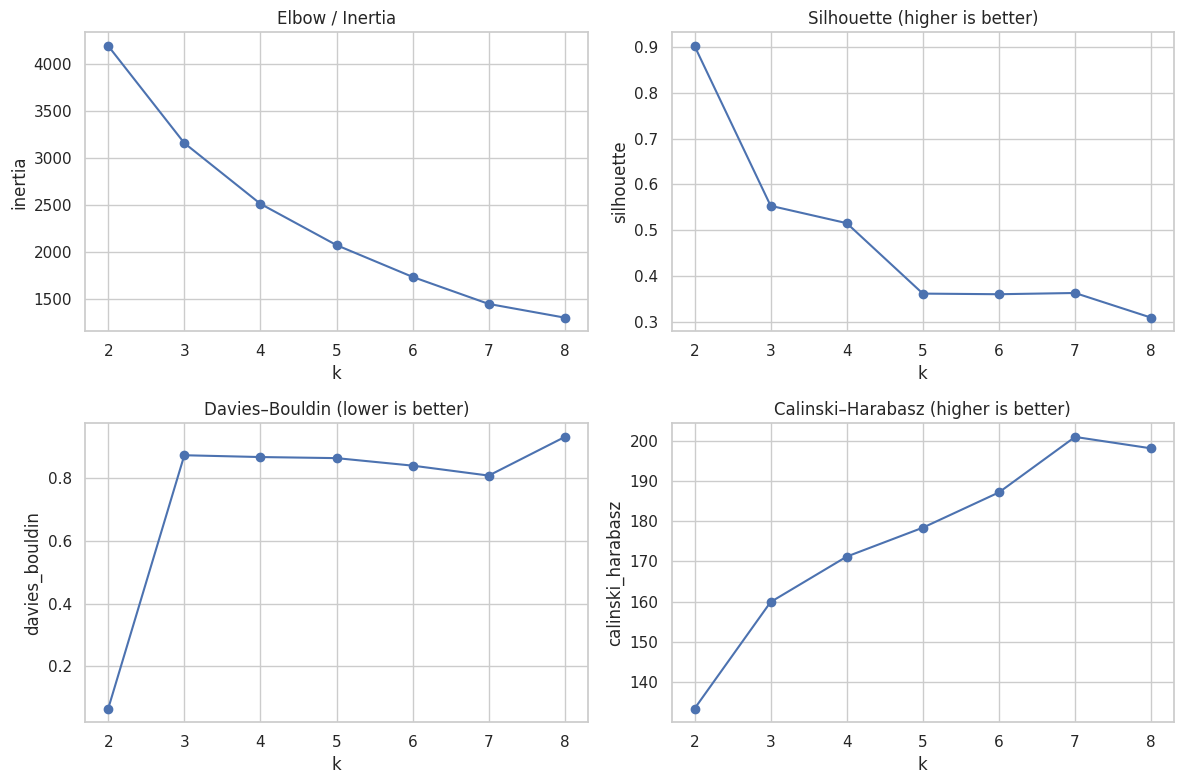

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, metric, title in [
    (axes[0,0], "inertia", "Elbow / Inertia"),
    (axes[0,1], "silhouette", "Silhouette (higher is better)"),
    (axes[1,0], "davies_bouldin", "Davies–Bouldin (lower is better)"),
    (axes[1,1], "calinski_harabasz", "Calinski–Harabasz (higher is better)")
]:
    ax.plot(kmeans_results["k"], kmeans_results[metric], marker="o")
    ax.set_xlabel("k"); ax.set_ylabel(metric); ax.set_title(title)
plt.tight_layout(); plt.show()

### Task D2. Choose an optimal k and justify it.

The following cell selects the k with the highest Silhouette score as a **starting recommendation**, not an automatic final truth. Inspect the elbow and other indices too, and justify the final choice using customer-segmentation context.

In [23]:
chosen_k = int(kmeans_results.loc[kmeans_results["silhouette"].idxmax(), "k"])
print("Starting recommendation from highest Silhouette:", chosen_k)
print("Compare with elbow, Davies–Bouldin, Calinski–Harabasz, and whether the resulting groups are interpretable.")
best_kmeans = kmeans_models[chosen_k]
kmeans_labels = best_kmeans.labels_
cleaned_df["KMeans_Cluster"] = kmeans_labels

Starting recommendation from highest Silhouette: 2
Compare with elbow, Davies–Bouldin, Calinski–Harabasz, and whether the resulting groups are interpretable.


### Task D3. Hierarchical clustering: Ward and Complete linkage dendrograms; cophenetic correlations.

Ward cophenetic correlation: 0.5395
Complete cophenetic correlation: 0.8975


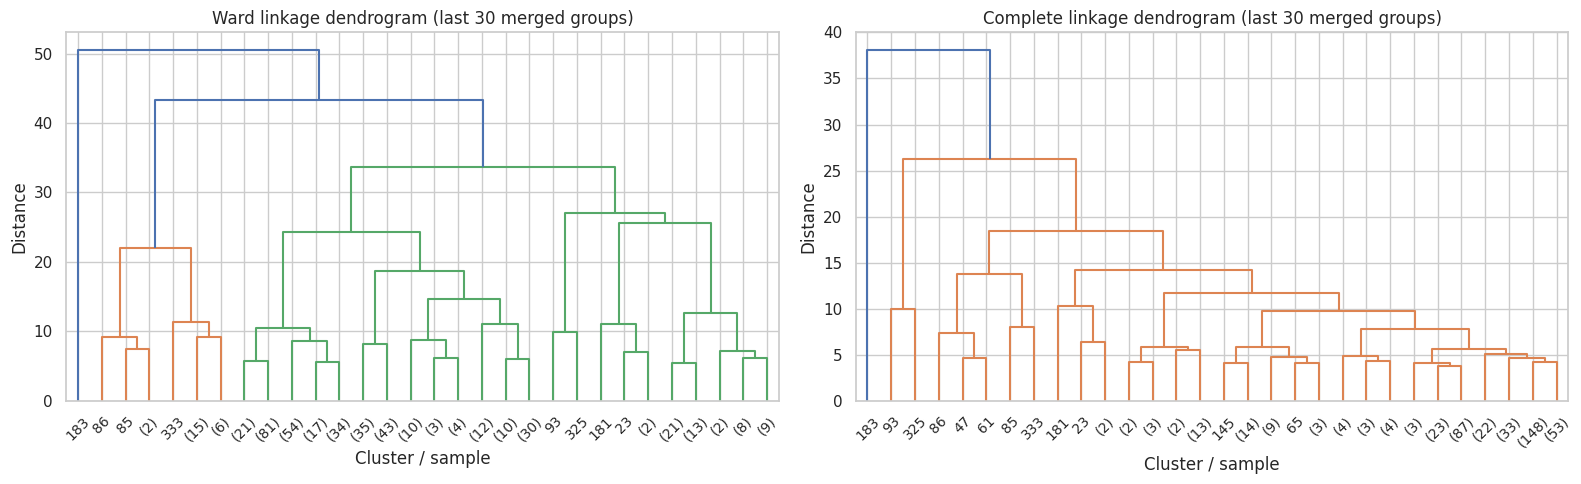

In [24]:
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist
# Use scaled feature matrix. For very large datasets, sample before drawing dendrograms.
Z_ward = linkage(X_scaled, method="ward")
Z_complete = linkage(X_scaled, method="complete")
condensed_dist = pdist(X_scaled)
coph_ward, _ = cophenet(Z_ward, condensed_dist)
coph_complete, _ = cophenet(Z_complete, condensed_dist)
print(f"Ward cophenetic correlation: {coph_ward:.4f}")
print(f"Complete cophenetic correlation: {coph_complete:.4f}")
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
dendrogram(Z_ward, truncate_mode="lastp", p=30, ax=axes[0])
axes[0].set_title("Ward linkage dendrogram (last 30 merged groups)")
axes[0].set_xlabel("Cluster / sample"); axes[0].set_ylabel("Distance")
dendrogram(Z_complete, truncate_mode="lastp", p=30, ax=axes[1])
axes[1].set_title("Complete linkage dendrogram (last 30 merged groups)")
axes[1].set_xlabel("Cluster / sample"); axes[1].set_ylabel("Distance")
plt.tight_layout(); plt.show()

### Task D4. Evaluate hierarchical cuts of 2–6 clusters and compare with K-means.

In [25]:
from sklearn.cluster import AgglomerativeClustering
hier_rows = []
hier_labels_by_method = {}
for method in ["ward", "complete"]:
    for k in range(2, 7):
        model = AgglomerativeClustering(n_clusters=k, linkage=method)
        labels = model.fit_predict(X_scaled)
        hier_labels_by_method[(method, k)] = labels
        hier_rows.append({
            "linkage": method, "k": k,
            "silhouette": silhouette_score(X_scaled, labels),
            "davies_bouldin": davies_bouldin_score(X_scaled, labels)
        })
hier_results = pd.DataFrame(hier_rows)
display(hier_results.round(4))
print("K-means chosen solution:")
display(kmeans_results[kmeans_results["k"] == chosen_k].round(4))

,linkage,k,silhouette,davies_bouldin
0,ward,2,0.9032,0.0647
1,ward,3,0.5670,0.6411
2,ward,4,0.4082,0.9333
3,ward,5,0.3807,0.8778
4,ward,6,0.3387,0.8026
5,complete,2,0.9032,0.0647
6,complete,3,0.7990,0.3487
7,complete,4,0.7554,0.4617
8,complete,5,0.7175,0.5870
9,complete,6,0.7136,0.6697


K-means chosen solution:


,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,4189.8812,0.9032,0.0647,133.4438


## Part E — Second EDA and statistical inference

### Task E1. Cluster centroids in original units.

In [27]:
# Step 1: Define the six spending categories
spending_features = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen"
]

# Step 2: Check that K-means cluster labels exist
if "KMeans_Cluster" not in cleaned_df.columns:
    raise ValueError(
        "KMeans_Cluster is missing. Run K-means clustering first."
    )

# Step 3: Calculate mean spending per cluster
cluster_profile = (
    cleaned_df.groupby("KMeans_Cluster")[spending_features]
    .mean()
    .round(2)
)

# Step 4: Count customers in each cluster
cluster_sizes = (
    cleaned_df["KMeans_Cluster"]
    .value_counts()
    .sort_index()
    .rename("n")
)

# Step 5: Combine profiles and cluster sizes
cluster_profile = cluster_profile.join(cluster_sizes)

# Step 6: Display results
print("K-means Cluster Profiles:")
display(cluster_profile)

K-means Cluster Profiles:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,n
KMeans_Cluster,,,,,,,
0,11943.7,5709.36,7923.44,2995.71,2887.51,1419.13,439
1,36847.0,43950.00,20170.00,36534.00,239.00,47943.00,1


In [29]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

cleaned_df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

### Task E2. Test numeric differences between clusters.

Use one-way ANOVA as a basic test. The notebook also reports Kruskal–Wallis, a non-parametric alternative. With very small groups or violated assumptions, prefer the non-parametric result and discuss limitations.

In [31]:
import numpy as np
import pandas as pd
from scipy.stats import f_oneway, kruskal

# Step 1: Define the six spending categories
spending_features = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen"
]

# Step 2: Check that cluster labels exist
if "KMeans_Cluster" not in cleaned_df.columns:
    raise ValueError("Run K-means clustering before conducting these tests.")

# Step 3: Test differences across clusters
test_rows = []

for col in spending_features:
    groups = [
        group[col].dropna().values
        for _, group in cleaned_df.groupby("KMeans_Cluster")
    ]

    groups = [group for group in groups if len(group) > 0]

    if len(groups) >= 2:
        anova_p = f_oneway(*groups).pvalue
        kw_p = kruskal(*groups).pvalue
    else:
        anova_p = np.nan
        kw_p = np.nan

    test_rows.append({
        "Feature": col,
        "ANOVA_p": anova_p,
        "Kruskal_Wallis_p": kw_p
    })

# Step 4: Display results
results = pd.DataFrame(test_rows)

display(results.round(6))

# Step 5: Interpret the p-values
print("\nInterpretation at significance level 0.05:")

for _, row in results.iterrows():
    feature = row["Feature"]

    if row["ANOVA_p"] < 0.05:
        anova_result = "Significant difference in group means"
    else:
        anova_result = "No significant difference in group means"

    if row["Kruskal_Wallis_p"] < 0.05:
        kw_result = "Significant difference in distributions"
    else:
        kw_result = "No significant difference in distributions"

    print(f"\n{feature}:")
    print(f"  ANOVA: {anova_result}")
    print(f"  Kruskal-Wallis: {kw_result}")

,Feature,ANOVA_p,Kruskal_Wallis_p
0,Fresh,0.049091,0.118103
1,Milk,0.000000,0.088288
2,Grocery,0.198362,0.150769
3,Frozen,0.000000,0.085388
4,Detergents_Paper,0.579572,0.342776
5,Delicassen,0.000000,0.083966



Interpretation at significance level 0.05:

Fresh:
  ANOVA: Significant difference in group means
  Kruskal-Wallis: No significant difference in distributions

Milk:
  ANOVA: Significant difference in group means
  Kruskal-Wallis: No significant difference in distributions

Grocery:
  ANOVA: No significant difference in group means
  Kruskal-Wallis: No significant difference in distributions

Frozen:
  ANOVA: Significant difference in group means
  Kruskal-Wallis: No significant difference in distributions

Detergents_Paper:
  ANOVA: No significant difference in group means
  Kruskal-Wallis: No significant difference in distributions

Delicassen:
  ANOVA: Significant difference in group means
  Kruskal-Wallis: No significant difference in distributions


### Task E3. Chi-square association tests for Gender and AgeGroup.

In [33]:
from scipy.stats import chi2_contingency
import pandas as pd

# Step 1: Initialize a list to store test results
chi_rows = []

# Step 2: Test association between Channel and K-means clusters
if "Channel" in cleaned_df.columns:
    tab_channel = pd.crosstab(
        cleaned_df["Channel"],
        cleaned_df["KMeans_Cluster"]
    )

    print("Channel × K-means Cluster Contingency Table:")
    display(tab_channel)

    if tab_channel.shape[0] > 1 and tab_channel.shape[1] > 1:
        chi2, p, dof, expected = chi2_contingency(tab_channel)

        chi_rows.append({
            "Variable": "Channel",
            "Chi-square": chi2,
            "Degrees_of_freedom": dof,
            "P_value": p
        })

# Step 3: Test association between Region and K-means clusters
if "Region" in cleaned_df.columns:
    tab_region = pd.crosstab(
        cleaned_df["Region"],
        cleaned_df["KMeans_Cluster"]
    )

    print("\nRegion × K-means Cluster Contingency Table:")
    display(tab_region)

    if tab_region.shape[0] > 1 and tab_region.shape[1] > 1:
        chi2, p, dof, expected = chi2_contingency(tab_region)

        chi_rows.append({
            "Variable": "Region",
            "Chi-square": chi2,
            "Degrees_of_freedom": dof,
            "P_value": p
        })

# Step 4: Display the summary of results
chi_results = pd.DataFrame(chi_rows)

print("\nChi-square Test Results:")
display(chi_results.round(6))

# Step 5: Interpret the results
for _, row in chi_results.iterrows():
    if row["P_value"] < 0.05:
        interpretation = "Significant association with cluster membership"
    else:
        interpretation = "No statistically significant association"

    print(f'{row["Variable"]}: {interpretation}')

Channel × K-means Cluster Contingency Table:


KMeans_Cluster,0,1
Channel,,
1,297,1
2,142,0



Region × K-means Cluster Contingency Table:


KMeans_Cluster,0,1
Region,,
1,77,0
2,47,0
3,315,1



Chi-square Test Results:


,Variable,Chi-square,Degrees_of_freedom,P_value
0,Channel,0.000000,1,1.000000
1,Region,0.393299,2,0.821479


Channel: No statistically significant association
Region: No statistically significant association


## Part F — Visualisation, reflection and reporting

### Task F1. Plot cluster assignments and summarize cluster profiles.

Variance explained by the two PCA components: 74.63%


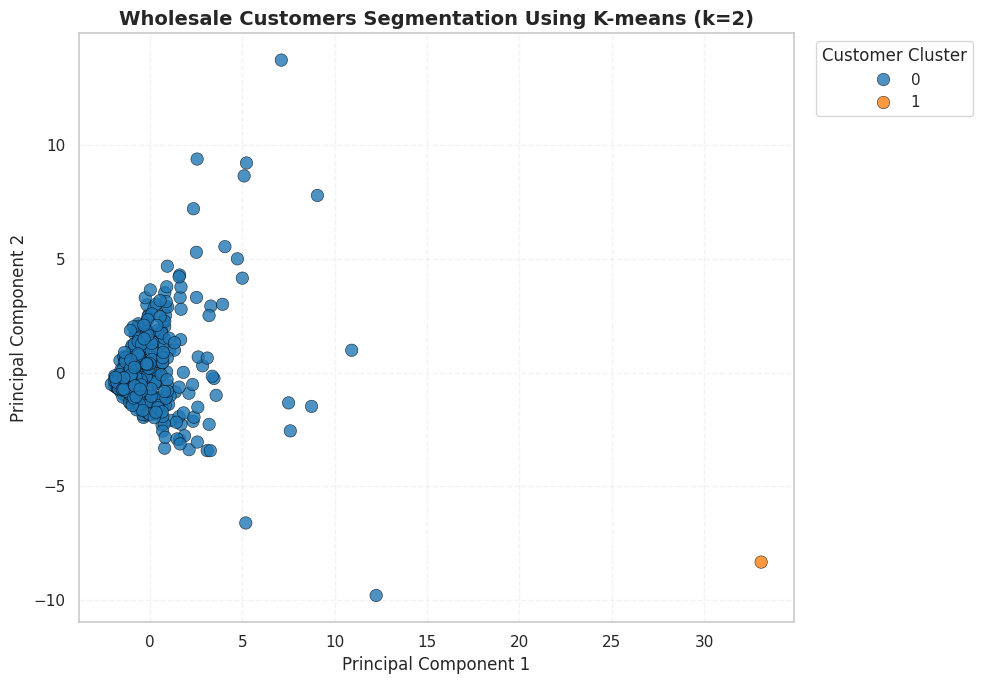

Average Spending Profile of Each Customer Cluster:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,n
KMeans_Cluster,,,,,,,
0,11943.7,5709.36,7923.44,2995.71,2887.51,1419.13,439
1,36847.0,43950.00,20170.00,36534.00,239.00,47943.00,1


In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.decomposition import PCA

# Step 1: Create PCA coordinates from the scaled spending features
pca = PCA(n_components=2)
pca_coordinates = pca.fit_transform(X_scaled)

# Step 2: Add PCA coordinates to the cleaned dataset
cleaned_df["PCA1"] = pca_coordinates[:, 0]
cleaned_df["PCA2"] = pca_coordinates[:, 1]

# Step 3: Check the percentage of variance explained
variance_explained = pca.explained_variance_ratio_.sum() * 100
print(f"Variance explained by the two PCA components: {variance_explained:.2f}%")

# Step 4: Plot the K-means clusters
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=cleaned_df,
    x="PCA1",
    y="PCA2",
    hue="KMeans_Cluster",
    palette="tab10",
    s=80,
    alpha=0.8,
    edgecolor="black",
    linewidth=0.4
)

plt.title(
    f"Wholesale Customers Segmentation Using K-means (k={chosen_k})",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Customer Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.25)
plt.tight_layout()
plt.show()

# Step 5: Display the cluster profiles
print("Average Spending Profile of Each Customer Cluster:")
display(cluster_profile)

### Task F2. Reflection prompts (write your answers in the report/slides)

1. What customer characteristics distinguish each cluster (age, income, spending score)?
2. Did the clustering metrics agree on the best number of clusters? Why or why not?
3. Which linkage method had the higher cophenetic correlation, and what does that indicate about how well it preserves pairwise distances?
4. Compare the best hierarchical cut with K-means using Silhouette and Davies–Bouldin values.
5. Limitations: scaling choices affect distances; K-means favours roughly spherical clusters; dendrograms become crowded for large datasets; Gender is excluded from the primary distance calculation.
6. Improvement: compare a mixed-data approach such as k-prototypes, or test stability across several random seeds.

### Optional stability check — repeat K-means with different seeds.

In [37]:
stability_rows = []
for seed in [0, 7, 21, 42, 77, 123]:
    model = KMeans(n_clusters=chosen_k, n_init=10, random_state=seed)
    labels = model.fit_predict(X_scaled)
    stability_rows.append({"seed": seed, "silhouette": silhouette_score(X_scaled, labels)})
stability = pd.DataFrame(stability_rows)
display(stability)
print(f"Silhouette mean ± std: {stability['silhouette'].mean():.4f} ± {stability['silhouette'].std():.4f}")

,seed,silhouette
0,0,0.903215
1,7,0.903215
2,21,0.903215
3,42,0.903215
4,77,0.903215
5,123,0.903215


Silhouette mean ± std: 0.9032 ± 0.0000


## Export outputs
Save the cleaned data, labels, and summary tables for your report.

In [38]:
cleaned_df.to_csv("mall_customers_with_clusters.csv", index=False)
kmeans_results.to_csv("mall_kmeans_metrics.csv", index=False)
hier_results.to_csv("mall_hierarchical_metrics.csv", index=False)
cluster_profile.to_csv("mall_cluster_profiles.csv")
print("Saved CSV outputs to the current working directory.")

Saved CSV outputs to the current working directory.
